Silakan upload gambar RGB


Saving sepeda.jfif to sepeda (3).jfif

===== INFORMASI CITRA =====
Citra RGB      : (1308, 736, 3)
Citra Grayscale: (1308, 736)

===== UKURAN CITRA =====
Tinggi : 1308 Piksel
Lebar  : 736 Piksel
Jumlah : 962688 Piksel

Total piksel histogram: 962688

===== HISTOGRAM SETIAP INTENSITAS =====
Intensitas   0: 1210 piksel
Intensitas   1: 1315 piksel
Intensitas   2: 1246 piksel
Intensitas   3: 1052 piksel
Intensitas   4: 1185 piksel
Intensitas   5: 1415 piksel
Intensitas   6: 1471 piksel
Intensitas   7: 1800 piksel
Intensitas   8: 1744 piksel
Intensitas   9: 1948 piksel
Intensitas  10: 2069 piksel
Intensitas  11: 2118 piksel
Intensitas  12: 2387 piksel
Intensitas  13: 2242 piksel
Intensitas  14: 2253 piksel
Intensitas  15: 2317 piksel
Intensitas  16: 2402 piksel
Intensitas  17: 2435 piksel
Intensitas  18: 2573 piksel
Intensitas  19: 2624 piksel
Intensitas  20: 2651 piksel
Intensitas  21: 2809 piksel
Intensitas  22: 2669 piksel
Intensitas  23: 2789 piksel
Intensitas  24: 2761 piksel
Intensita

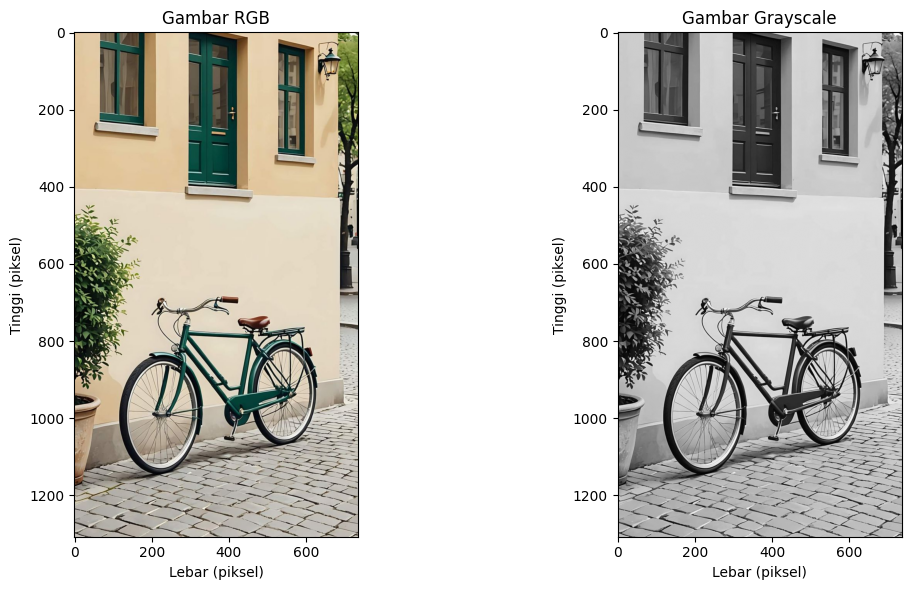

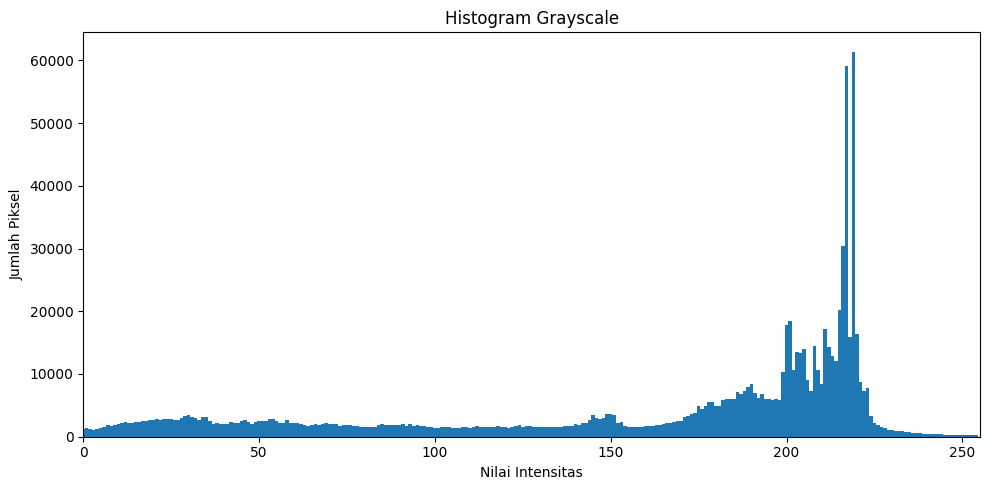


===== RINGKASAN HASIL AKHIR =====
Tinggi gambar       : 1308 piksel
Lebar gambar        : 736 piksel
Total keseluruhan   : 962688 piksel
Intensitas dominan  : 219
Jumlah piksel dominan: 61393
Total histogram     : 962688

Program berhasil dijalankan!


In [8]:
# ==========================================================
# TUGAS PENGOLAHAN CITRA DIGITAL
# KONVERSI RGB KE GRAYSCALE DAN ANALISIS HISTOGRAM
# ==========================================================

import imageio.v2 as imageio
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. UPLOAD GAMBAR
print("Silakan upload gambar RGB")
uploaded = files.upload()
nama_file = next(iter(uploaded))

# 2. MEMBACA GAMBAR
img = imageio.imread(nama_file)

# Mengubah gambar menjadi RGB 3 kanal
if img.ndim == 2:
    img_rgb = np.stack([img, img, img], axis=-1)
else:
    img_rgb = img[:, :, :3]

print("\n===== INFORMASI CITRA =====")
print("Citra RGB      :", img_rgb.shape)

# 3. KONVERSI RGB KE GRAYSCALE
R = img_rgb[:, :, 0].astype(float)
G = img_rgb[:, :, 1].astype(float)
B = img_rgb[:, :, 2].astype(float)

img_gray = (
    0.299 * R +
    0.587 * G +
    0.114 * B
).astype(np.uint8)

print("Citra Grayscale:", img_gray.shape)

# 4. MENGHITUNG TINGGI, LEBAR, TOTAL PIKSEL
tinggi, lebar = img_gray.shape
jumlah_piksel = img_gray.size

print("\n===== UKURAN CITRA =====")
print("Tinggi :", tinggi, "Piksel")
print("Lebar  :", lebar, "Piksel")
print("Jumlah :", jumlah_piksel, "Piksel")

# 5. MENGHITUNG HISTOGRAM INTENSITAS 0-255
histogram = np.bincount(
    img_gray.ravel(),
    minlength=256
)

print("\nTotal piksel histogram:", histogram.sum())

# 6. MENAMPILKAN JUMLAH PIKSEL SETIAP INTENSITAS
print("\n===== HISTOGRAM SETIAP INTENSITAS =====")

for intensitas in range(256):
    print(
        f"Intensitas {intensitas:3d}: "
        f"{histogram[intensitas]} piksel"
    )

# 7. MENENTUKAN INTENSITAS DOMINAN
intensitas_dominan = np.argmax(histogram)
jumlah_dominan = histogram[intensitas_dominan]

print("\n===== HASIL INTENSITAS DOMINAN =====")
print("Intensitas Dominan :", intensitas_dominan)
print("Jumlah Intensitas  :", jumlah_dominan)

# 8. MENAMPILKAN GAMBAR RGB DAN GRAYSCALE
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Gambar RGB")
plt.xlabel("Lebar (piksel)")
plt.ylabel("Tinggi (piksel)")

plt.subplot(1, 2, 2)
plt.imshow(img_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Gambar Grayscale")
plt.xlabel("Lebar (piksel)")
plt.ylabel("Tinggi (piksel)")

plt.tight_layout()
plt.savefig("gambar_rgb_grayscale.png", dpi=150)
plt.show()

# 9. MENAMPILKAN HISTOGRAM
plt.figure(figsize=(10, 5))

plt.bar(range(256), histogram, width=1)
plt.title("Histogram Grayscale")
plt.xlabel("Nilai Intensitas")
plt.ylabel("Jumlah Piksel")
plt.xlim(0, 255)

plt.tight_layout()
plt.savefig("histogram_grayscale.png", dpi=150)
plt.show()

# 10. MENAMPILKAN RINGKASAN AKHIR
print("\n===== RINGKASAN HASIL AKHIR =====")
print("Tinggi gambar       :", tinggi, "piksel")
print("Lebar gambar        :", lebar, "piksel")
print("Total keseluruhan   :", jumlah_piksel, "piksel")
print("Intensitas dominan  :", intensitas_dominan)
print("Jumlah piksel dominan:", jumlah_dominan)
print("Total histogram     :", histogram.sum())

# 11. MENYIMPAN GAMBAR GRAYSCALE
imageio.imwrite("hasil_grayscale.png", img_gray)

print("\nProgram berhasil dijalankan!")